<a href="https://colab.research.google.com/github/SrishanthGorla/SERAI/blob/main/MITRE_ATLAS_Conceptual_Attack_Mapping.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Define the Threat-to-Lifecycle mapping for the RAG LLM Chatbot
threat_data = [
    {
        "Lifecycle Phase": "1. Ingestion & Storage",
        "Threat Scenario": "Knowledge base corpus poisoning",
        "ATLAS Tactic": "Resource Development",
        "Technique ID": "AML.T0020",
        "Technique Name": "Poison Training Data",
        "Severity": "High",
        "Mitigation": "Integrity checks, hash validation, document provenance"
    },
    {
        "Lifecycle Phase": "2. Supply Chain & Setup",
        "Threat Scenario": "Compromised base embeddings / tokenizers",
        "ATLAS Tactic": "Initial Access",
        "Technique ID": "AML.T0010",
        "Technique Name": "ML Supply Chain Compromise",
        "Severity": "Critical",
        "Mitigation": "Use Safetensors, verify artifact signatures, SBOM audit"
    },
    {
        "Lifecycle Phase": "3. User Interaction",
        "Threat Scenario": "System prompt override / jailbreaking",
        "ATLAS Tactic": "Execution",
        "Technique ID": "AML.T0054",
        "Technique Name": "LLM Prompt Injection",
        "Severity": "Critical",
        "Mitigation": "Input guardrails, structural prompt boundaries, classification checks"
    },
    {
        "Lifecycle Phase": "4. Retrieval & Response",
        "Threat Scenario": "PII / internal system prompt disclosure",
        "ATLAS Tactic": "Impact",
        "Technique ID": "AML.T0043",
        "Technique Name": "LLM Data Leakage",
        "Severity": "High",
        "Mitigation": "Contextual access control, automated output redaction/PII scrubbing"
    },
    {
        "Lifecycle Phase": "5. Production Monitoring",
        "Threat Scenario": "Systematic querying to extract system capabilities",
        "ATLAS Tactic": "Exfiltration",
        "Technique ID": "AML.T0024",
        "Technique Name": "Exfiltration via ML Inference API",
        "Severity": "Medium",
        "Mitigation": "API rate limiting, behavioral anomaly detection, prompt volume caps"
    }
]

# Convert to DataFrame
df_threats = pd.DataFrame(threat_data)

# Display formatted table
styled_table = df_threats.style.set_properties(**{
    'text-align': 'left',
    'white-space': 'pre-wrap'
}).set_table_styles([
    dict(selector='th', props=[('background-color', '#1e3d59'), ('color', 'white'), ('font-weight', 'bold')])
])

styled_table

,Lifecycle Phase,Threat Scenario,ATLAS Tactic,Technique ID,Technique Name,Severity,Mitigation
0,1. Ingestion & Storage,Knowledge base corpus poisoning,Resource Development,AML.T0020,Poison Training Data,High,"Integrity checks, hash validation, document provenance"
1,2. Supply Chain & Setup,Compromised base embeddings / tokenizers,Initial Access,AML.T0010,ML Supply Chain Compromise,Critical,"Use Safetensors, verify artifact signatures, SBOM audit"
2,3. User Interaction,System prompt override / jailbreaking,Execution,AML.T0054,LLM Prompt Injection,Critical,"Input guardrails, structural prompt boundaries, classification checks"
3,4. Retrieval & Response,PII / internal system prompt disclosure,Impact,AML.T0043,LLM Data Leakage,High,"Contextual access control, automated output redaction/PII scrubbing"
4,5. Production Monitoring,Systematic querying to extract system capabilities,Exfiltration,AML.T0024,Exfiltration via ML Inference API,Medium,"API rate limiting, behavioral anomaly detection, prompt volume caps"


In [2]:
# Save DataFrame to CSV
df_threats.to_csv("mitre_atlas_lifecycle_mapping.csv", index=False)
print("Saved mapping table to 'mitre_atlas_lifecycle_mapping.csv'")

# Build MITRE ATLAS Navigator Layer v4.x compatible JSON
navigator_layer = {
    "name": "Customer Support RAG Threat Assessment",
    "versions": {
        "layer": "4.5",
        "navigator": "4.8.0"
    },
    "domain": "mitre-atlas",
    "description": "Lifecycle threat mapping for an enterprise LLM RAG chatbot.",
    "techniques": [
        {
            "techniqueID": "AML.T0020",
            "score": 8,
            "comment": "Data Ingestion: Poisoning knowledge store",
            "enabled": True
        },
        {
            "techniqueID": "AML.T0010",
            "score": 10,
            "comment": "Supply Chain: Compromised tokenizer/embeddings",
            "enabled": True
        },
        {
            "techniqueID": "AML.T0054",
            "score": 10,
            "comment": "Inference: Prompt injection / jailbreak",
            "enabled": True
        },
        {
            "techniqueID": "AML.T0043",
            "score": 8,
            "comment": "Output: Leaking internal company context",
            "enabled": True
        },
        {
            "techniqueID": "AML.T0024",
            "score": 5,
            "comment": "Monitoring: Extraction via inference queries",
            "enabled": True
        }
    ],
    "gradient": {
        "colors": ["#ffebee", "#ef5350", "#b71c1c"],
        "minValue": 0,
        "maxValue": 10
    }
}

# Export Navigator layer JSON
with open("atlas_navigator_layer.json", "w") as f:
    json.dump(navigator_layer, f, indent=4)

print("Saved Navigator layer to 'atlas_navigator_layer.json'")

Saved mapping table to 'mitre_atlas_lifecycle_mapping.csv'
Saved Navigator layer to 'atlas_navigator_layer.json'


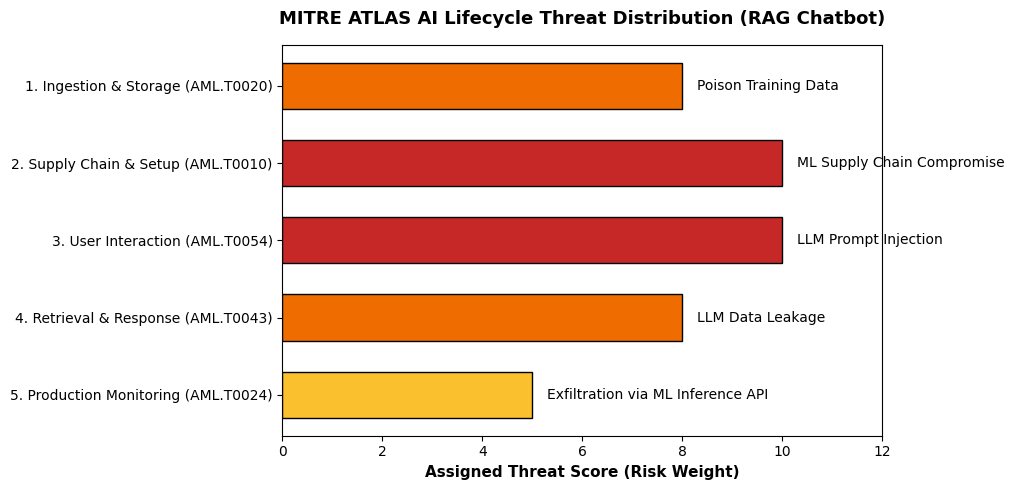

In [3]:
plt.figure(figsize=(10, 5))
severity_color_map = {"Critical": "#c62828", "High": "#ef6c00", "Medium": "#fbc02d"}
colors = [severity_color_map[s] for s in df_threats["Severity"]]

bars = plt.barh(df_threats["Lifecycle Phase"] + " (" + df_threats["Technique ID"] + ")",
                [10 if s == "Critical" else 8 if s == "High" else 5 for s in df_threats["Severity"]],
                color=colors, edgecolor='black', height=0.6)

plt.xlabel("Assigned Threat Score (Risk Weight)", fontsize=11, fontweight='bold')
plt.title("MITRE ATLAS AI Lifecycle Threat Distribution (RAG Chatbot)", fontsize=13, fontweight='bold', pad=15)
plt.xlim(0, 12)
plt.gca().invert_yaxis()

# Annotate bars with technique names
for bar, name in zip(bars, df_threats["Technique Name"]):
    plt.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2, name, va='center', fontsize=10, weight='medium')

plt.tight_layout()
plt.savefig("atlas_threat_summary.png", dpi=300)
plt.show()